# 16 — Walk-Forward (Rolling-Origin) sebagai Uji Ketahanan

Split utama 70/10/20 menghasilkan **satu** periode uji (2023-04..2026-08) yang kebetulan reli panjang. Walk-forward menguji hal yang sama pada **beberapa** periode uji berurutan:

- jendela belajar **melebar** (expanding); setiap fold memiliki blok uji ± 1 tahun hari kerja (`WF_FOLD_LEN`), `WF_N_FOLDS` fold berurutan sampai data terakhir;
- baris yang boleh dipakai belajar pada fold *k* hanyalah origin yang **label h-harinya sudah diketahui sebelum origin uji pertama** (embargo h hari otomatis); 10% terakhirnya dipakai validasi (early stopping), sisanya train;
- Drift tiap fold = rata-rata return h-hari pada train fold itu;
- model: 10 ML (`WF_ML_MODELS`) + dua DL wakil (DPformer, DL terbaik otomatis) dengan lr/wd **default** (1e-3 / 1e-4): hasil MOSSA **tidak dipakai** karena MOSSA dituning pada validasi split utama (2021–2023) yang berada di dalam blok uji beberapa fold — memakainya akan membocorkan informasi.

Uji DM dihitung per fold dan **gabungan** seluruh fold (deret selisih-loss berurutan; koreksi HLN; BH). Tidak ada pemilihan model dari hasil ini.

Hasil per run: `results/walkforward/f<k>/runs/`. Perkiraan waktu FULL pada CPU 2 thread: ML sekitar 10–15 menit; DL (48 run) sekitar 1,5–2,5 jam.

In [1]:
import sys, os, json, time, warnings

# Batasi thread CPU supaya laptop tetap responsif selama training berjam-jam.
# Default 2 thread. Ubah lewat env TA_THREADS. Harus di kernel BARU (sebelum numpy/tensorflow aktif).
N_THREADS = int(os.environ.get('TA_THREADS', '2'))
for _v in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS'):
    os.environ.setdefault(_v, str(N_THREADS))

sys.path.insert(0, os.path.join('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
try:
    tf.config.threading.set_intra_op_parallelism_threads(N_THREADS)
    tf.config.threading.set_inter_op_parallelism_threads(1)
except RuntimeError:
    print('[PERHATIAN] TensorFlow sudah aktif di kernel ini, batas thread tidak berlaku. Restart kernel.')

from src.config import (OUT, HORIZONS, SETUPS, ML_MODELS, DL_MODELS, ALL_MODELS, LANG, PROTOCOL, ML_REV, QUICK,
                        SEQ_LEN, EPOCHS, PATIENCE, BASE_LR, BASE_WD, DL_BATCH, DL_UNITS)
from src import analysis as A, plots as P, stats as S, runners as R
from src.pipeline import SEED, load_mossa, free_memory
from src.runners import load_data, data_fingerprint

P.set_lang(LANG)
RES = os.path.join(OUT, 'results')
RUNS = os.path.join(RES, 'runs')
FIGS = os.path.join(OUT, 'figures')
MODEL_DIR = os.path.join(RES, 'models')
for _d in (RES, RUNS, FIGS, MODEL_DIR):
    os.makedirs(_d, exist_ok=True)

df, p, exo = load_data('..')
DATA_HASH = data_fingerprint(df)
print(f'Data: {len(p)} hari kerja, {p.index[0].date()} s.d. {p.index[-1].date()} | sidik jari {DATA_HASH}'
      + (' | MODE QUICK (hasil hanya uji kelancaran)' if QUICK else ''))


def simpan(fig, nama):
    P.save_fig(fig, nama, FIGS)
    plt.show()
    plt.close(fig)

import json
from src.config import WF_N_FOLDS, WF_FOLD_LEN, WF_HORIZONS, WF_ML_MODELS
from src.pipeline import walkforward_splits
wakil = A.load_wakil(RES)
reps = [wakil['dpformer'], wakil['dl']]
models_wf = list(WF_ML_MODELS) + reps
WF_DIR = os.path.join(RES, 'walkforward')

folds_by_h = {h: walkforward_splits(p, h, WF_N_FOLDS, WF_FOLD_LEN) for h in WF_HORIZONS}
rows = []
for h in WF_HORIZONS:
    for fd in folds_by_h[h]:
        tr_d, va_d, te = fd['split']
        rows.append({'h': h, 'fold': fd['fold'], 'n_train': len(tr_d), 'n_val': len(va_d), 'akhir_val': va_d[-1].date(),
                     'uji_mulai': fd['start'].date(), 'uji_akhir': fd['end'].date(), 'n_uji': len(te)})
display(pd.DataFrame(rows))
print('DL wakil (lr/wd default):', reps, '| ML:', WF_ML_MODELS)

Data: 4325 hari kerja, 2010-01-05 s.d. 2026-08-03 | sidik jari 7aea8db80d44


,h,fold,n_train,n_val,akhir_val,uji_mulai,uji_akhir,n_uji
0,5,1,2480,275,2020-07-27,2020-08-04,2021-08-02,260
1,5,2,2714,301,2021-07-26,2021-08-03,2022-08-01,260
2,5,3,2948,327,2022-07-25,2022-08-02,2023-07-31,260
3,5,4,3182,353,2023-07-24,2023-08-01,2024-07-29,260
4,5,5,3416,379,2024-07-22,2024-07-30,2025-07-28,260
5,5,6,3650,405,2025-07-21,2025-07-29,2026-07-27,260
6,20,1,2453,272,2020-06-15,2020-07-14,2021-07-12,260
7,20,2,2687,298,2021-06-14,2021-07-13,2022-07-11,260
8,20,3,2921,324,2022-06-13,2022-07-12,2023-07-10,260
9,20,4,3155,350,2023-06-12,2023-07-11,2024-07-08,260


DL wakil (lr/wd default): ['dpformer', 'gru_att'] | ML: ['lightgbm', 'xgboost', 'rf', 'catboost', 'gbm', 'svr', 'extra_trees', 'hist_gbm', 'adaboost', 'elasticnet']


## Pagar kebocoran walk-forward (otomatis)

Untuk setiap (horizon, fold): label h-hari seluruh baris train **dan** validasi harus sudah diketahui **sebelum** origin uji pertama (embargo); urutan waktu train < validasi < uji; blok uji saling bersambung tanpa tumpang tindih dan berakhir di origin terakhir yang punya target. Gagal = `AssertionError`.

In [2]:
pos_of = {d: i for i, d in enumerate(p.index)}
for h in WF_HORIZONS:
    prev_end = None
    for fd in folds_by_h[h]:
        tr_d, va_d, te = fd['split']
        s = te[0]
        tr_pos = [pos_of[d] for d in tr_d]
        va_pos = [pos_of[d] for d in va_d]
        assert max(tr_pos) + h < s and max(va_pos) + h < s, f'h={h} fold {fd["fold"]}: label train/validasi menyentuh periode uji'
        assert tr_pos[-1] < va_pos[0] and va_pos[-1] < s, f'h={h} fold {fd["fold"]}: urutan train < validasi < uji dilanggar'
        assert te == list(range(s, s + len(te))), f'h={h} fold {fd["fold"]}: origin uji tidak berurutan'
        assert te[-1] + h <= len(p) - 1, f'h={h} fold {fd["fold"]}: target uji melewati akhir data'
        if prev_end is not None:
            assert s == prev_end + 1, f'h={h} fold {fd["fold"]}: blok uji tidak bersambung dengan fold sebelumnya'
        prev_end = te[-1]
    assert prev_end + h == len(p) - 1, f'h={h}: blok terakhir tidak berakhir di origin terakhir yang punya target'
print('[OK] pagar kebocoran walk-forward lolos untuk semua horizon dan fold')

[OK] pagar kebocoran walk-forward lolos untuk semua horizon dan fold


In [3]:
def make_ml_runner(k):
    def run(lb, m, h):
        split = folds_by_h[h][k - 1]['split']
        return R.run_ml(p, exo if lb == 'multivariat' else None, lb, m, h, split=split, rev=ML_REV, data_hash=DATA_HASH)
    return run


def make_dl_runner(k):
    def run(lb, m, h):
        split = folds_by_h[h][k - 1]['split']
        return R.run_dl(p, exo if lb == 'multivariat' else None, lb, m, h, lr=BASE_LR, wd=BASE_WD, split=split, data_hash=DATA_HASH)
    return run


gagal = []
for k in range(1, WF_N_FOLDS + 1):
    runs_k = os.path.join(WF_DIR, f'f{k}', 'runs')
    print(f'\n===== fold {k}/{WF_N_FOLDS} =====')
    c1 = R.run_grid([(s, m, h) for s in SETUPS for m in WF_ML_MODELS for h in WF_HORIZONS], make_ml_runner(k), runs_k,
                    rev=ML_REV, data_hash=DATA_HASH)
    c2 = R.run_grid([(s, m, h) for s in SETUPS for m in reps for h in WF_HORIZONS], make_dl_runner(k), runs_k, data_hash=DATA_HASH)
    gagal += c1['daftar_gagal'] + c2['daftar_gagal']
assert not gagal, gagal


===== fold 1/6 =====
RUN  univariat/lightgbm/h5 ... Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's rmse: 0.0240215
OK MAE=10,413 (0.5s)
RUN  univariat/lightgbm/h20 ... Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's rmse: 0.047871
OK MAE=20,743 (0.2s)
RUN  univariat/xgboost/h5 ... OK MAE=10,394 (0.7s)
RUN  univariat/xgboost/h20 ... OK MAE=20,717 (0.4s)
RUN  univariat/rf/h5 ... OK MAE=10,294 (3.0s)
RUN  univariat/rf/h20 ... OK MAE=20,649 (2.5s)
RUN  univariat/catboost/h5 ... OK MAE=10,418 (0.7s)
RUN  univariat/catboost/h20 ... OK MAE=20,769 (0.4s)
RUN  univariat/gbm/h5 ... OK MAE=10,474 (5.5s)
RUN  univariat/gbm/h20 ... OK MAE=22,325 (5.1s)
RUN  univariat/svr/h5 ... OK MAE=10,088 (0.5s)
RUN  univariat/svr/h20 ... OK MAE=19,414 (0.6s)
RUN  univariat/extra_trees/h5 ... OK MAE=10,353 (2.8s)
RUN  univariat/extra_trees/h20 ... OK MAE=20,296 (2.6s)
RUN  univariat/hist_

## Hasil per fold dan gabungan

In [4]:
per_fold, pooled = A.wf_tables(RES, p, SETUPS, models_wf, WF_HORIZONS, folds_by_h)
per_fold.to_csv(os.path.join(RES, 'walkforward_per_fold.csv'), index=False)
pooled.to_csv(os.path.join(RES, 'walkforward_gabungan.csv'), index=False)
assert len(pooled) == len(SETUPS) * len(models_wf) * len(WF_HORIZONS), 'Ada kombinasi walk-forward yang belum lengkap.'

print('Ringkasan uji DM gabungan (seluruh fold) terhadap Drift:')
rg = []
for s in SETUPS:
    for h in WF_HORIZONS:
        t = pooled[(pooled.setup == s) & (pooled.horizon == h)]
        rg.append({'setup': s, 'h': h, 'n_model': len(t), 'rel<1': int((t.rel < 1).sum()), 'p<0.05': int((t.p_one_hln < 0.05).sum()),
                   'lolos BH (per setup)': int((t.q_bh < 0.05).sum()), 'median rel': round(float(t.rel.median()), 4)})
display(pd.DataFrame(rg))

print('Jumlah fold (dari %d) di mana model lebih baik dari Drift (rasio MSE < 1):' % WF_N_FOLDS)
display(pooled.pivot_table(index='model', columns=['setup', 'horizon'], values='n_fold_lebih_baik').reindex(models_wf).astype(int))
print('Median rasio MSE (seluruh model) per fold:')
display(per_fold.groupby(['setup', 'horizon', 'blok']).rel_mse.median().unstack('blok').round(3))

Ringkasan uji DM gabungan (seluruh fold) terhadap Drift:


,setup,h,n_model,rel<1,p<0.05,lolos BH (per setup),median rel
0,univariat,5,12,0,0,0,1.0195
1,univariat,20,12,7,0,0,0.9731
2,multivariat,5,12,3,0,0,1.0174
3,multivariat,20,12,8,0,0,0.9976


Jumlah fold (dari 6) di mana model lebih baik dari Drift (rasio MSE < 1):


setup       multivariat    univariat   
horizon              5  20        5  20
model                                  
lightgbm              3  3         3  4
xgboost               3  3         4  4
rf                    3  3         2  3
catboost              4  3         5  3
gbm                   1  1         1  3
svr                   1  2         1  1
extra_trees           3  3         3  4
hist_gbm              0  1         0  1
adaboost              2  3         2  3
elasticnet            3  4         2  4
dpformer              2  3         2  3
gru_att               5  4         3  3

Median rasio MSE (seluruh model) per fold:


blok                     1      2      3      4      5      6
setup       horizon                                          
multivariat 5        1.000  1.026  0.998  1.022  0.976  1.042
            20       1.004  1.051  1.069  0.989  0.916  1.009
univariat   5        0.998  1.008  1.024  1.028  0.984  1.058
            20       1.007  1.079  1.085  0.992  0.923  0.933

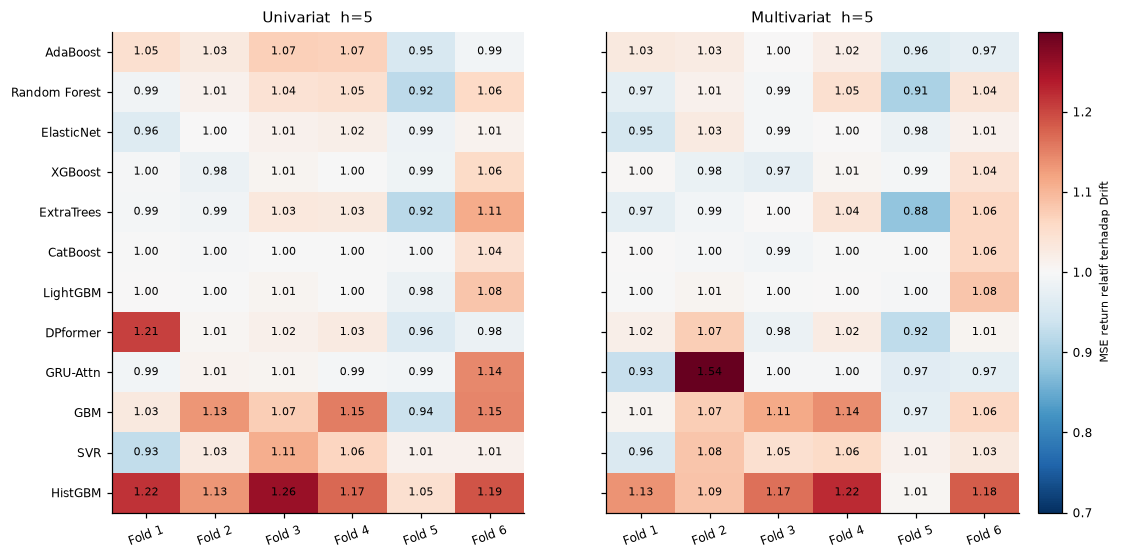

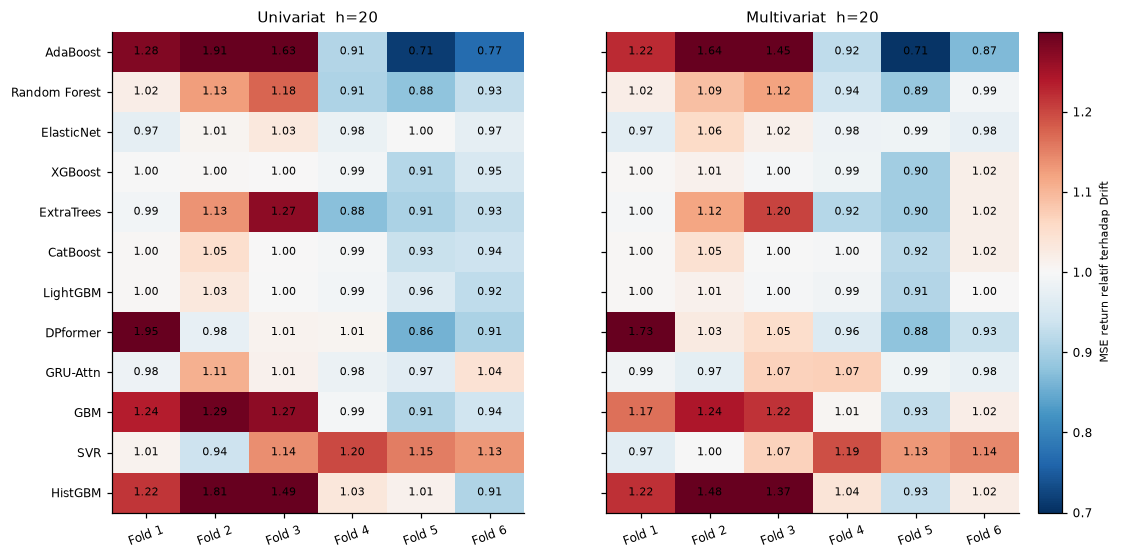

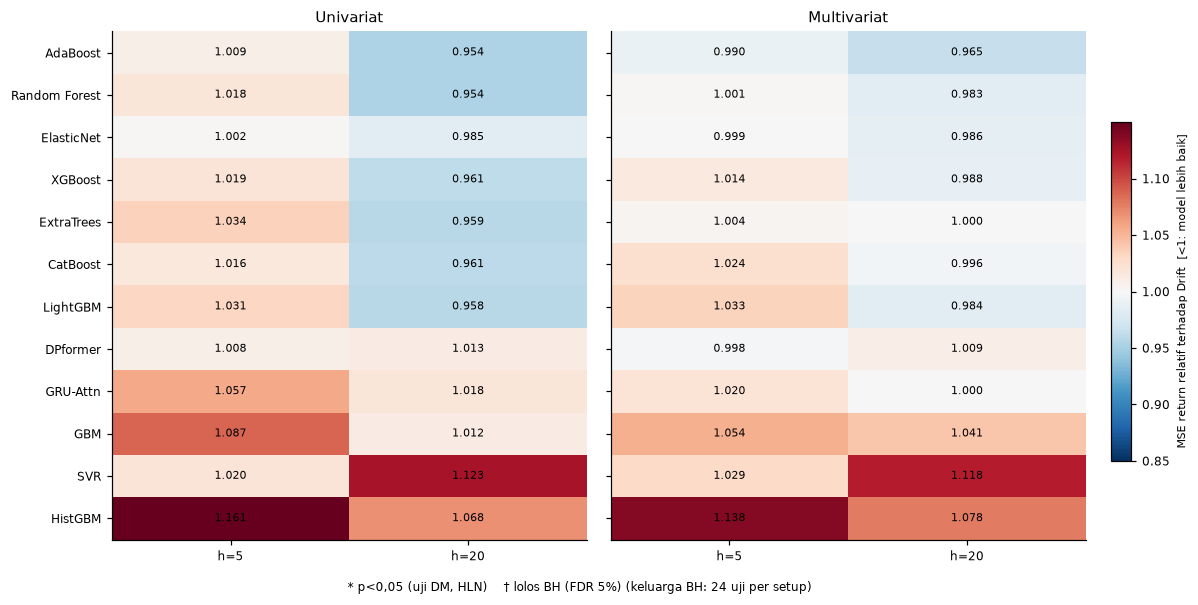

In [5]:
urut = pooled.groupby('model').rel.mean().sort_values().index.tolist()
for h in WF_HORIZONS:
    fig = P.fig_block_heatmap(per_fold, urut, list(range(1, WF_N_FOLDS + 1)), SETUPS, h=h, col_key='fold', lim=0.3)
    simpan(fig, f'fig_walkforward_fold_h{h}')
fig = P.fig_dm_heatmap(pooled, urut, WF_HORIZONS, lim=0.15,
                       bh_note=f'keluarga BH: {len(models_wf) * len(WF_HORIZONS)} uji per setup')
simpan(fig, 'fig_walkforward_gabungan')

**Cara membaca.**

- Peta per fold menunjukkan **apakah keunggulan terhadap Drift berulang** pada periode berbeda. Model yang unggul di satu fold tetapi kalah di fold lain tidak memberi keunggulan yang bisa diandalkan.
- Uji gabungan memberi kekuatan statistik lebih besar daripada satu periode uji; bila tidak ada model yang lolos koreksi BH, kesimpulan yang jujur adalah **tidak ada bukti bahwa model-model ini mengalahkan Drift pada return**, konsisten dengan hasil utama.
- Hasil walk-forward memakai lr/wd default untuk DL sehingga tidak langsung sebanding dengan DPformer-MOSSA di hasil utama; yang dibandingkan di sini adalah pola ketahanan, bukan peringkat final.